In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
# Change for your data
root_path = Path("/data/smfish/20260311_bartelle_smFISH_cryo_48hr_male")

In [3]:
output_dir = root_path / "big_fish" / "results" / "all_tiles_2D"
matrix_path = output_dir / "cellxgene_matrix.csv"
# spots_path_bit5 = os.path.join(output_dir, "spots_bit_5.csv")
matrix = pd.read_csv(matrix_path, usecols= ['cell_id', 'Angpt1', 'Crmp1', 'Dcx', 'Hdac11', 'Itgam', 'Notch2',
       'Ptch1', 'Serpine1', 'Shh', 'Slc1a3', 'Tcf12', 'Tek', 'Tgfb1', 'Tgfbi', 'Aif1', 'Nnat'])
print(matrix.shape)
print(matrix.head())

(9709, 17)
   cell_id  Angpt1   Crmp1    Dcx  Hdac11  Itgam  Notch2  Ptch1  Serpine1  \
0        0    2748  119363  10559   78683  13164   10057  18360      8594   
1        1       0       1      0       0      0       0      0         0   
2        3       0       0      0       0      0       0      1         0   
3        5       0       1      0       0      0       0      3         0   
4        6       0      35      1      15      0       0      1         0   

    Shh  Slc1a3  Tcf12   Tek  Tgfb1  Tgfbi   Aif1   Nnat  
0  4103  103261   9700  8471  15820  13410  14236  13704  
1     0       1      0     0      0      0      0      0  
2     0       1      0     0      0      0      0      0  
3     0       9      0     0      0      0      0      3  
4     0       1      0     0      0      0      0      0  


In [4]:
matrix.columns

Index(['cell_id', 'Angpt1', 'Crmp1', 'Dcx', 'Hdac11', 'Itgam', 'Notch2',
       'Ptch1', 'Serpine1', 'Shh', 'Slc1a3', 'Tcf12', 'Tek', 'Tgfb1', 'Tgfbi',
       'Aif1', 'Nnat'],
      dtype='str')

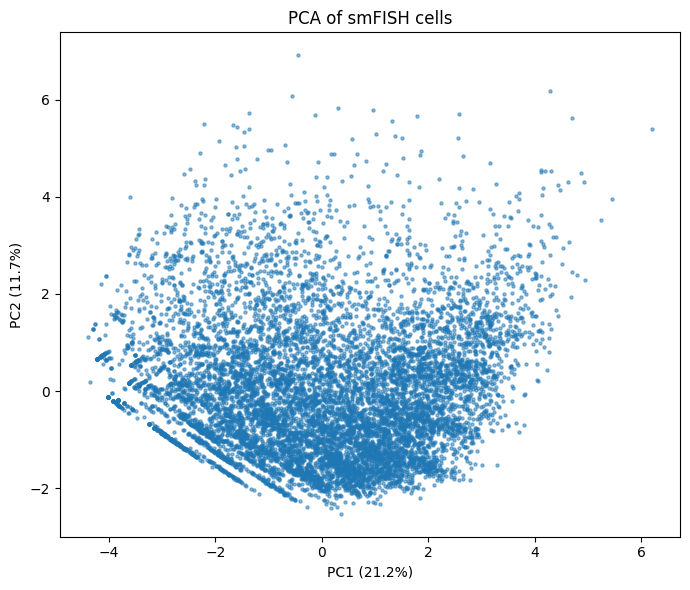

In [5]:
# Select gene counts and normalize each cell by its total counts
genes = matrix.columns.drop("cell_id")
# convert integer counts to floats
counts = matrix[genes].astype(float)

# Use a robust upper bound for each gene
gene_upper = counts.quantile(0.99, axis=0).replace(0, 1)

# Clip outliers, then scale every gene to approximately 0–10,000
gene_scaled = (
    counts.clip(upper=gene_upper, axis=1)
          .div(gene_upper, axis=1)
          .mul(10_000)
)

# natural-log transformation log(1+x)
# log transform the data because counts span orders of magnitude. Brings data values closer together
# gene expression data is heavily right skewed
log_counts = np.log1p(gene_scaled)

# Standardize genes and run PCA
scaled_counts = StandardScaler().fit_transform(log_counts)
pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled_counts)

# Plot cells in PCA space
plt.figure(figsize=(7, 6))
plt.scatter(pcs[:, 0], pcs[:, 1], s=5, alpha=0.5)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
plt.title("PCA of smFISH cells")
plt.tight_layout()
plt.show()

In [6]:
log_counts

,Angpt1,Crmp1,Dcx,Hdac11,Itgam,Notch2,Ptch1,Serpine1,Shh,Slc1a3,Tcf12,Tek,Tgfb1,Tgfbi,Aif1,Nnat
0,9.21044,9.210440,9.210440,9.210440,9.21044,9.21044,9.210440,9.21044,9.21044,9.210440,9.21044,9.21044,9.21044,9.21044,9.21044,9.210440
1,0.00000,4.311774,0.000000,0.000000,0.00000,0.00000,0.000000,0.00000,0.00000,5.500860,0.00000,0.00000,0.00000,0.00000,0.00000,0.000000
2,0.00000,0.000000,0.000000,0.000000,0.00000,0.00000,6.646690,0.00000,0.00000,5.500860,0.00000,0.00000,0.00000,0.00000,0.00000,0.000000
3,0.00000,4.311774,0.000000,0.000000,0.00000,0.00000,7.744437,0.00000,0.00000,7.694448,0.00000,0.00000,0.00000,0.00000,0.00000,7.135035
4,0.00000,7.854010,6.646690,7.419181,0.00000,0.00000,6.646690,0.00000,0.00000,5.500860,0.00000,0.00000,0.00000,0.00000,0.00000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9704,0.00000,5.401407,6.646690,0.000000,0.00000,0.00000,0.000000,0.00000,0.00000,8.492706,0.00000,0.00000,0.00000,0.00000,0.00000,0.000000
9705,0.00000,7.764434,7.339188,5.812138,0.00000,0.00000,0.000000,0.00000,0.00000,6.191963,0.00000,0.00000,0.00000,0.00000,0.00000,0.000000
9706,0.00000,7.434359,6.646690,6.099073,0.00000,0.00000,6.646690,0.00000,0.00000,5.500860,7.26513,0.00000,0.00000,0.00000,0.00000,0.000000
9707,0.00000,5.687960,0.000000,0.000000,0.00000,0.00000,6.646690,0.00000,0.00000,0.000000,0.00000,0.00000,0.00000,0.00000,0.00000,0.000000


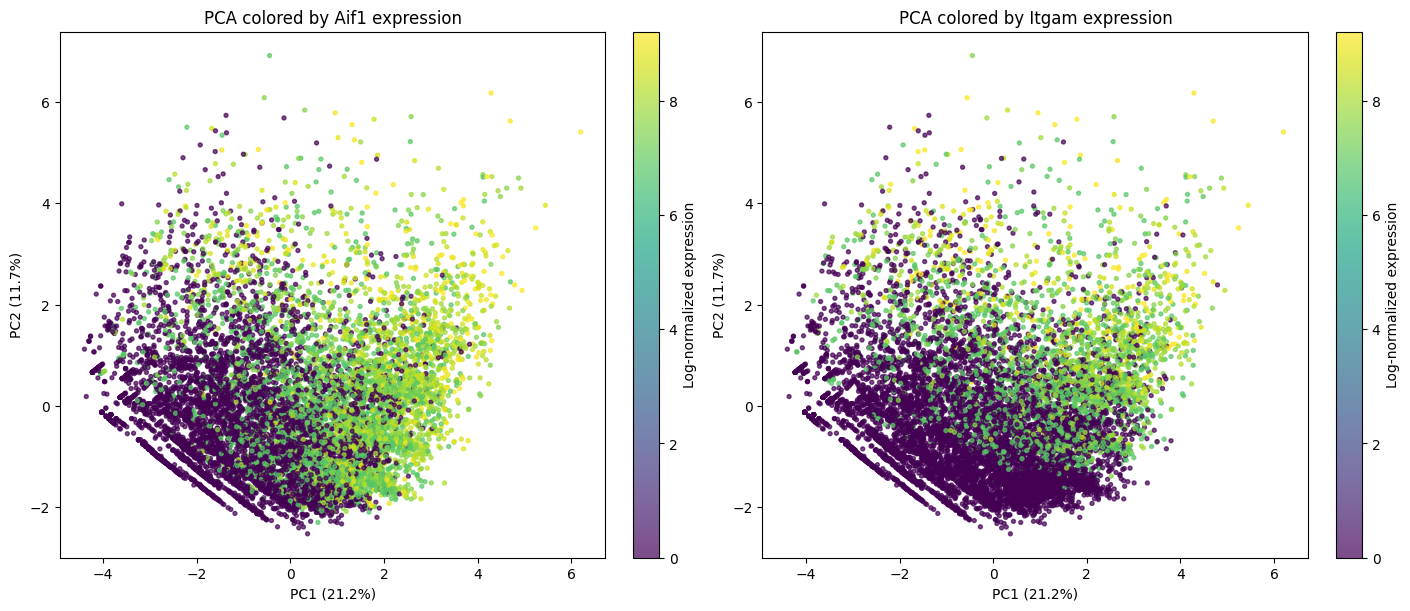

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Aif1", "Itgam"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

plt.show()

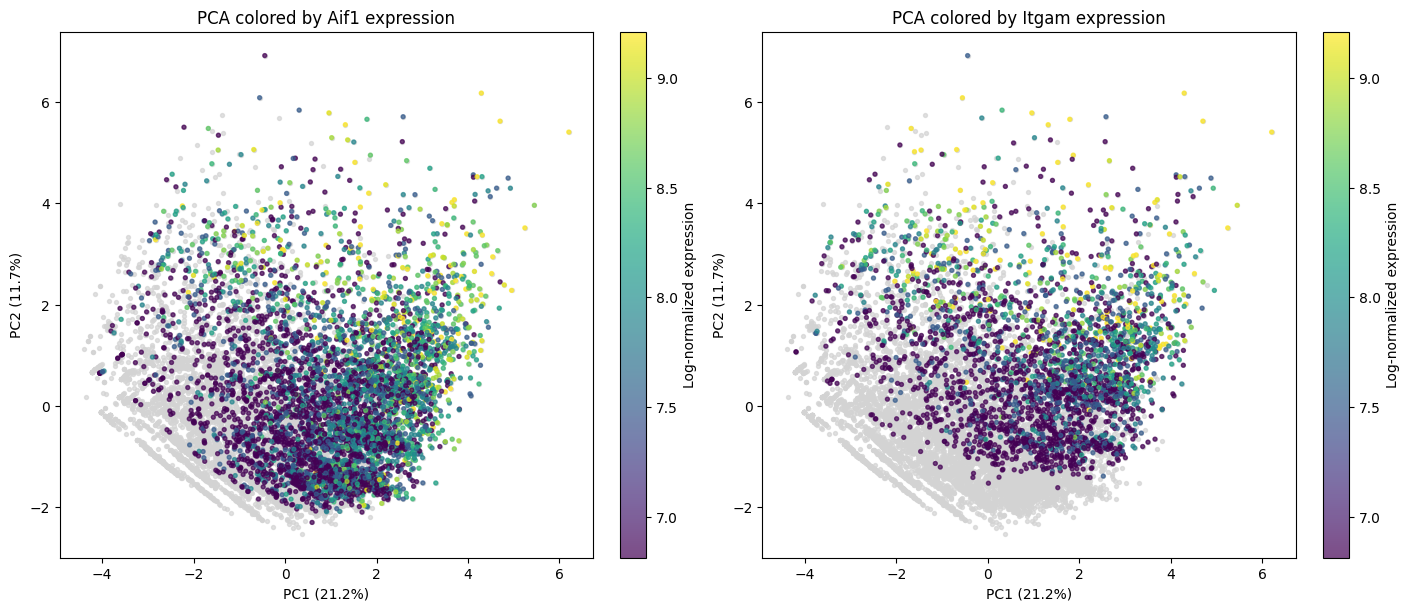

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Aif1", "Itgam"]):
    expression = log_counts[gene].to_numpy()
    positive = expression > 0

    # Plot all cells gray first
    ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        color="lightgray",
        s=8,
        alpha=0.7,
    )

    # Overlay cells with detected expression
    scatter = ax.scatter(
        pcs[positive, 0],
        pcs[positive, 1],
        c=expression[positive],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )

    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

plt.show()

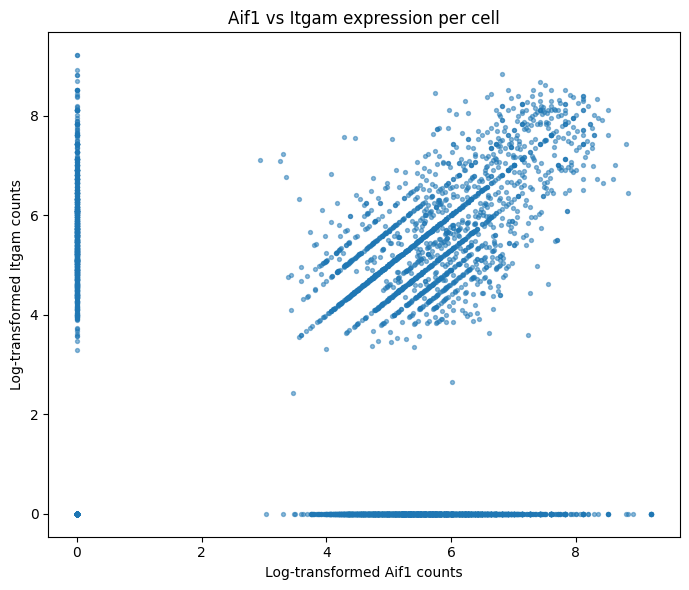

In [9]:
# # log_counts without gene scaling
# log_counts_no_scaling = np.log1p(counts)

# sum the total # of spots per cell
library_size = counts.sum(axis=1).replace(0, 1)

# library size normalization, then natural-log transformation log(1+x)
log_counts_lsn = (counts.div(library_size, axis=0) * 1e4).apply(np.log1p)


plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts_lsn["Aif1"],
    log_counts_lsn["Itgam"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log-transformed Aif1 counts")
plt.ylabel("Log-transformed Itgam counts")
plt.title("Aif1 vs Itgam expression per cell")
plt.tight_layout()
plt.show()

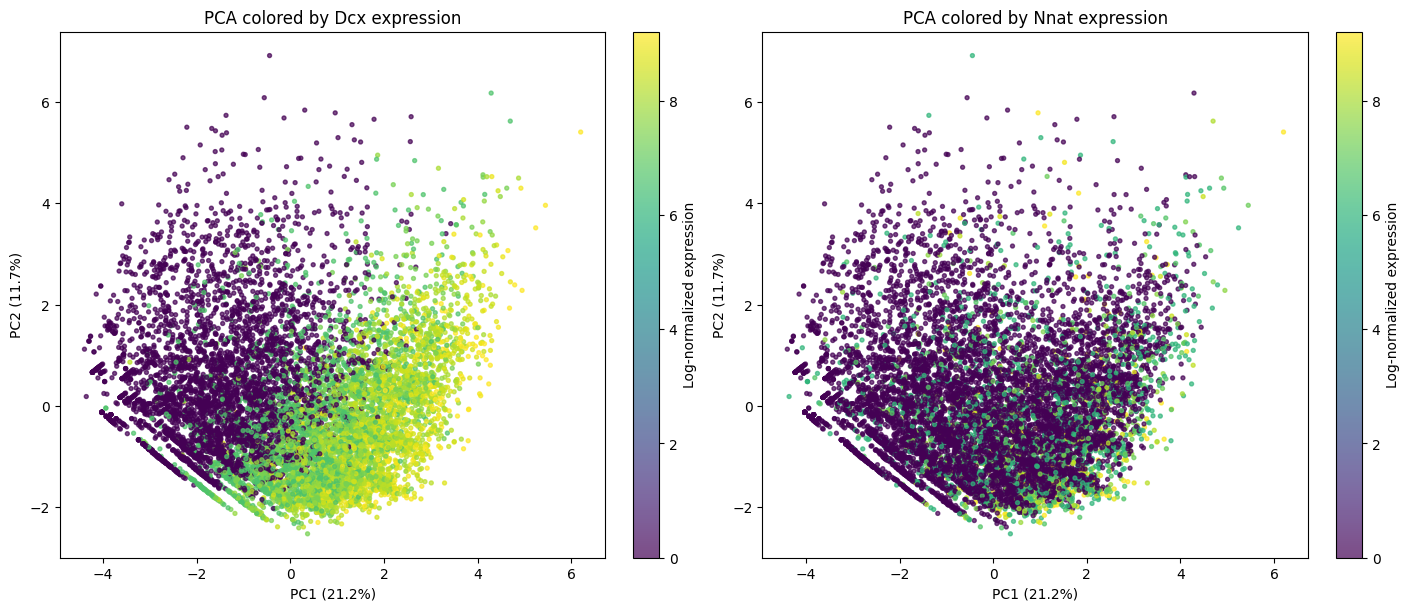

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Dcx", "Nnat"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

plt.show()

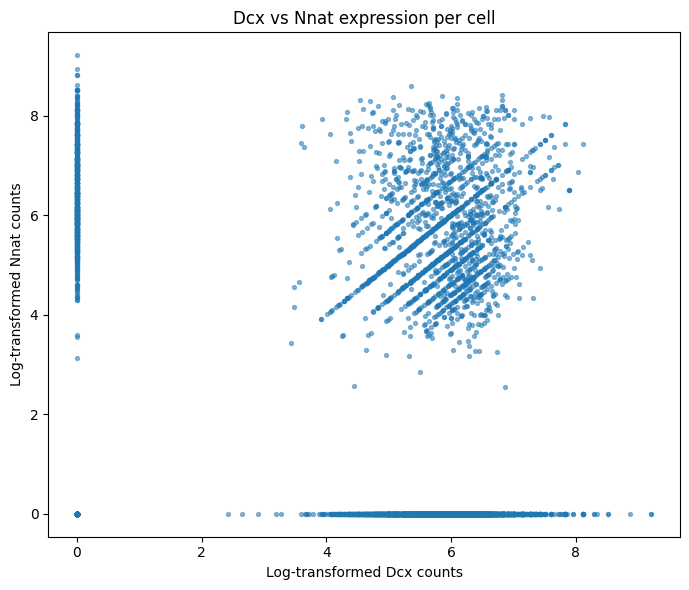

In [11]:
plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts_lsn["Dcx"],
    log_counts_lsn["Nnat"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log-transformed Dcx counts")
plt.ylabel("Log-transformed Nnat counts")
plt.title("Dcx vs Nnat expression per cell")
plt.tight_layout()
plt.show()

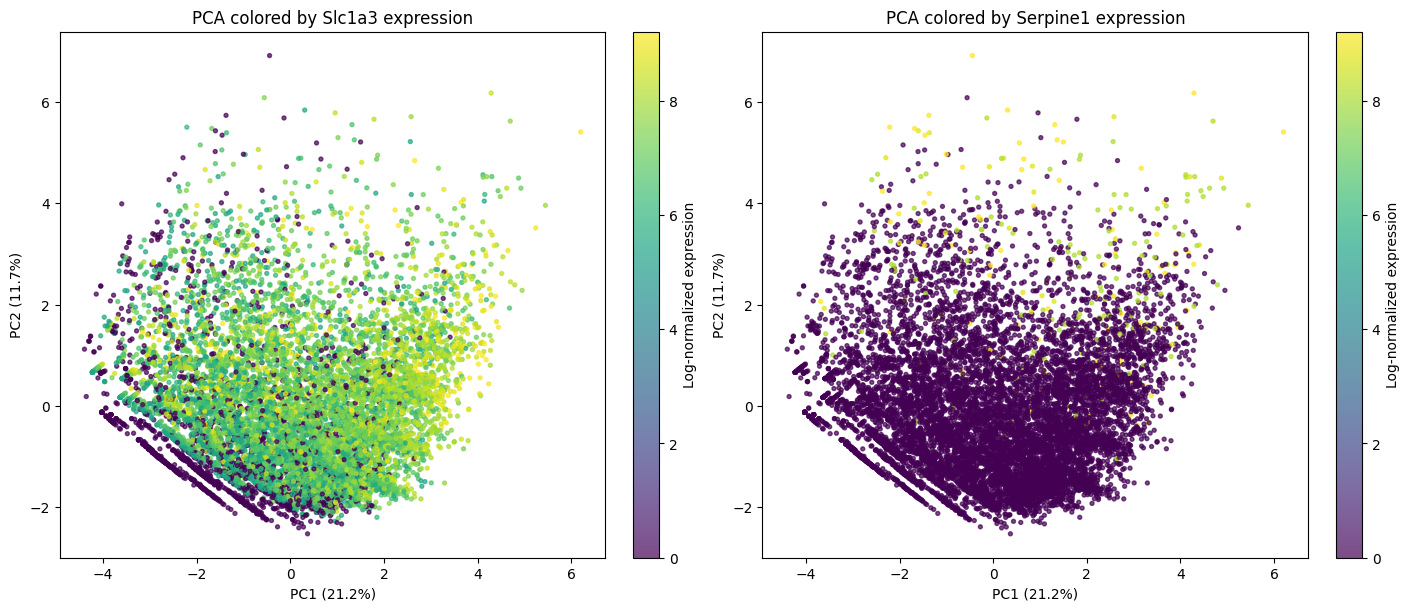

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Slc1a3", "Serpine1"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

plt.show()

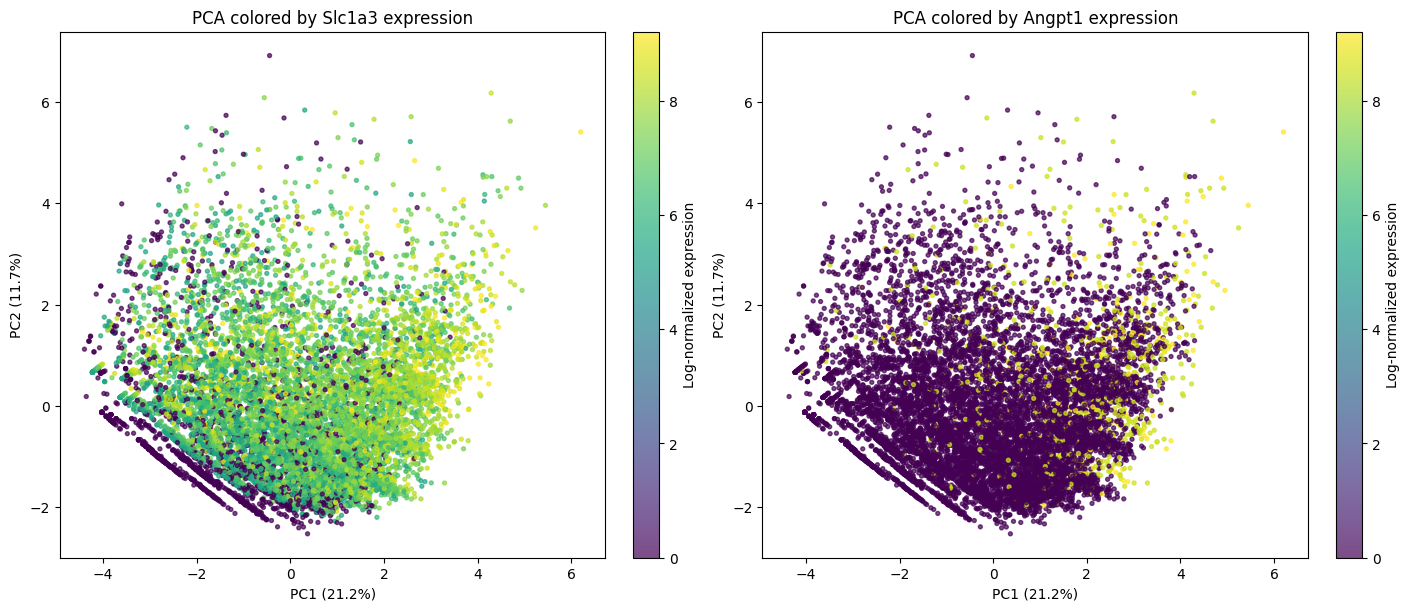

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Slc1a3", "Angpt1"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

plt.show()

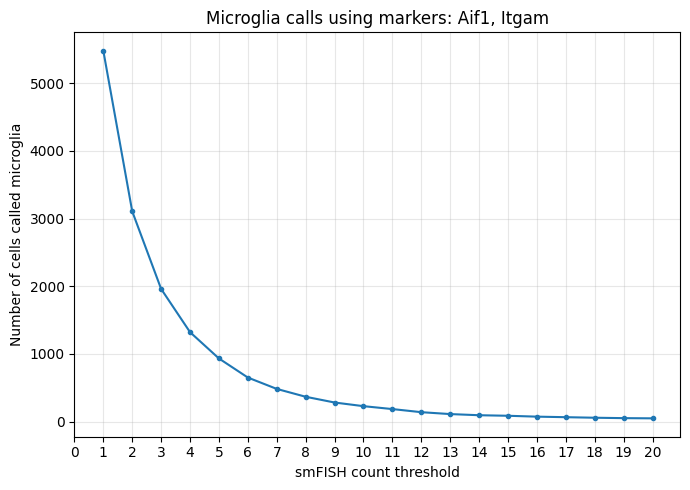

In [14]:
# Define marker genes for the cell type
marker_genes = ["Aif1", "Itgam"]

# Verify that all requested markers are available
missing_genes = set(marker_genes) - set(counts.columns)
if missing_genes:
    raise ValueError(f"Missing marker genes: {sorted(missing_genes)}")

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (counts[marker_genes] >= threshold).any(axis=1).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using markers: {', '.join(marker_genes)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

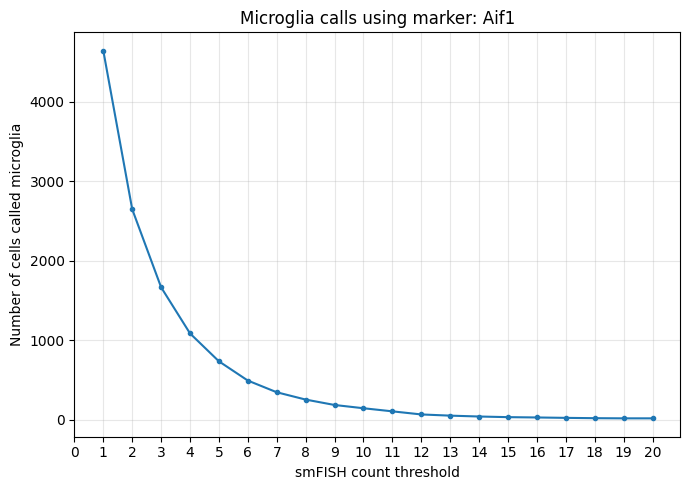

In [15]:
# Define marker genes for the cell type
marker_gene = ["Aif1"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

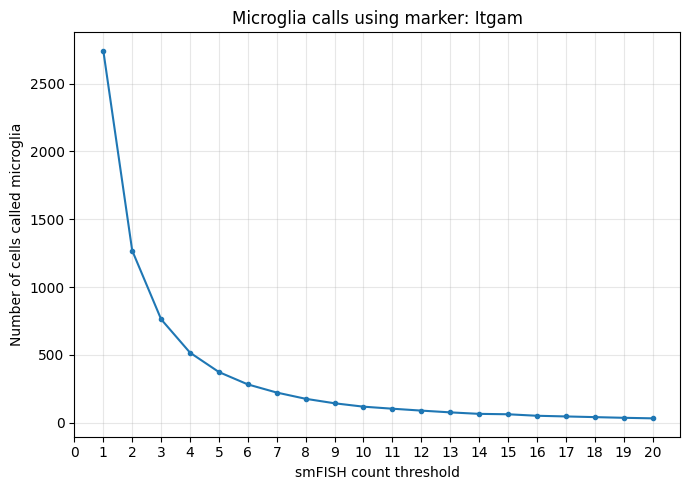

In [20]:
# Define marker genes for the cell type
marker_gene = ["Itgam"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

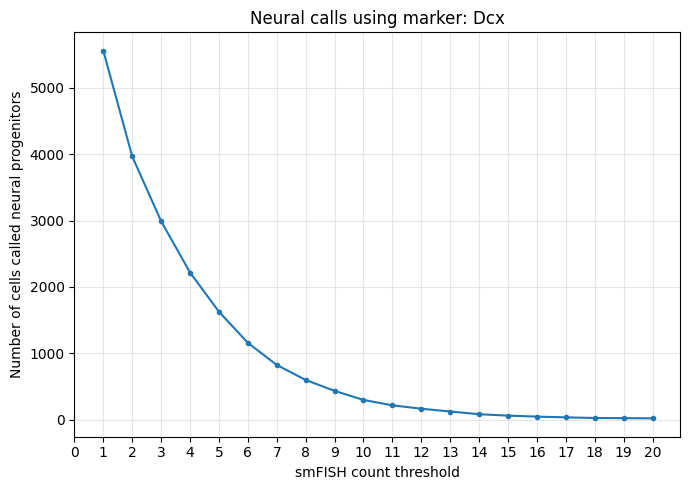

In [21]:
# Define marker genes for the cell type
marker_gene = ["Dcx"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

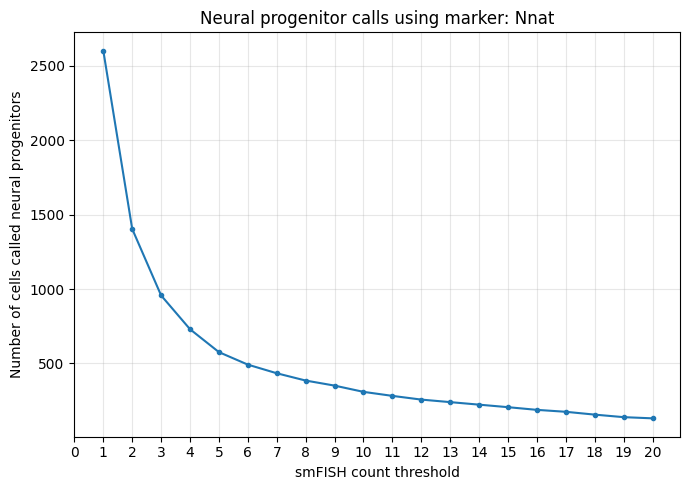

In [22]:
# Define marker genes for the cell type
marker_gene = ["Nnat"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

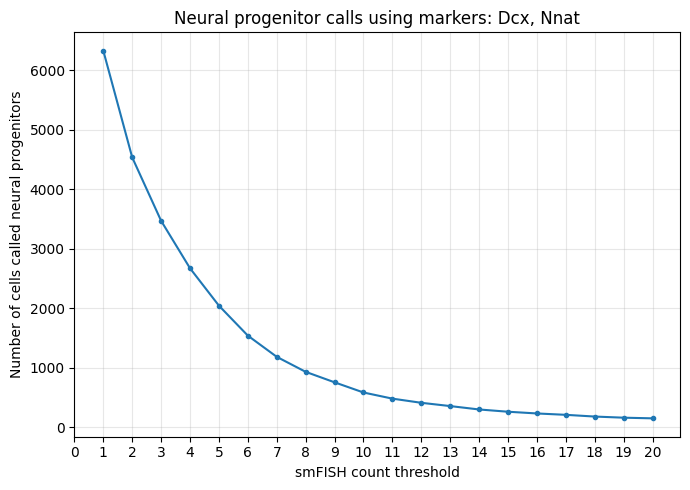

In [23]:
# Define marker genes for the cell type
marker_genes = ["Dcx", "Nnat"]

# Verify that all requested markers are available
missing_genes = set(marker_genes) - set(counts.columns)
if missing_genes:
    raise ValueError(f"Missing marker genes: {sorted(missing_genes)}")

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (counts[marker_genes] >= threshold).any(axis=1).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls using markers: {', '.join(marker_genes)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

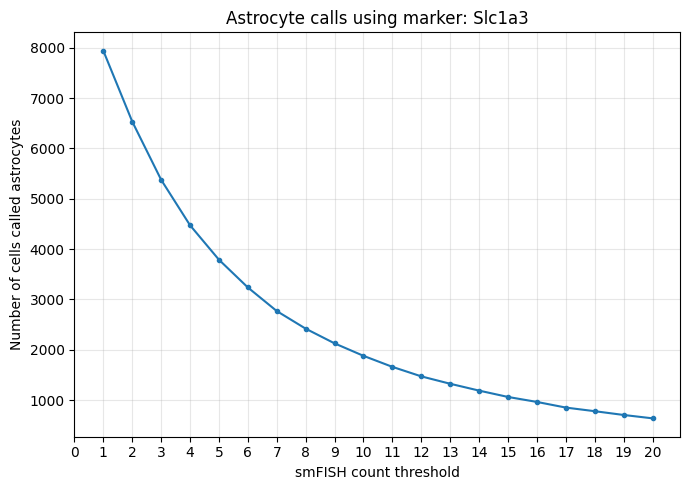

In [24]:
# Define marker genes for the cell type
marker_gene = ["Slc1a3"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
astrocyte_counts = [
    (counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, astrocyte_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called astrocytes")
plt.title(f"Astrocyte calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()